In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

file_path = (
    "C:/Users/RSCH/Desktop/DWD/Final project/"
    "Retail-Intelligence-Platform/datasets/"
    "amez_dataset_feature_engineered.xlsx"
)

data = pd.read_excel(
    file_path,
    sheet_name="Feature_Data"
)

data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])

print("Dataset shape:", data.shape)
print(data.head())
print(data.columns.tolist())

Dataset shape: (11992, 22)
       InvoiceID InvoiceDate                           CustomerID  \
0  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   
1  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   
2  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   
3  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   
4  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   

                              ProductID  \
0  8e4669ab-db13-4000-0bd7-f03200008e46   
1  93c93477-c69c-4000-0a0f-adee000093c9   
2  7ec257a3-2b97-4000-04df-ce3a00007ec2   
3  81c25c5c-d497-4000-0b2f-c5c5000081c2   
4  93c93477-c69c-4000-0a0f-adee000093c9   

                                ProductName           Category  \
0  Merino Wool Minimalist Crewneck Knitwear  Fashion & Apparel   
1       Bio-Peptide Restorative Night Crème  Beauty & Wellness   
2      Velocity Pro Carbon Running Sneakers  Fashion & Apparel   
3      Ergonomic Breathable Mesh De

In [2]:
required_columns = [
    "InvoiceDate",
    "ProductID",
    "Quantity"
]

missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

data = data.dropna(
    subset=["InvoiceDate", "ProductID", "Quantity"]
).copy()

data = data[data["Quantity"] >= 0].copy()

print("Rows available for forecasting:", len(data))
print("First date:", data["InvoiceDate"].min())
print("Last date:", data["InvoiceDate"].max())
print("Products:", data["ProductID"].nunique())

Rows available for forecasting: 11992
First date: 2026-01-01 00:00:00
Last date: 2026-08-15 01:45:53
Products: 121


In [3]:
data["Date"] = data["InvoiceDate"].dt.normalize()

daily_sales = (
    data.groupby(
        ["ProductID", "Date"],
        as_index=False
    )
    .agg(Demand=("Quantity", "sum"))
)

daily_sales = daily_sales.sort_values(
    ["ProductID", "Date"]
)

print(daily_sales.head(10))

                              ProductID       Date  Demand
0  0128933d-9879-4346-aafc-a8045c36b087 2026-01-15       2
1  0128933d-9879-4346-aafc-a8045c36b087 2026-01-16       6
2  0128933d-9879-4346-aafc-a8045c36b087 2026-01-17       2
3  0128933d-9879-4346-aafc-a8045c36b087 2026-01-19       3
4  0128933d-9879-4346-aafc-a8045c36b087 2026-01-24       3
5  0128933d-9879-4346-aafc-a8045c36b087 2026-01-25       4
6  0128933d-9879-4346-aafc-a8045c36b087 2026-01-26       2
7  0128933d-9879-4346-aafc-a8045c36b087 2026-01-28       2
8  0128933d-9879-4346-aafc-a8045c36b087 2026-01-31       4
9  0128933d-9879-4346-aafc-a8045c36b087 2026-02-01       1


In [4]:
all_dates = pd.date_range(
    start=daily_sales["Date"].min(),
    end=daily_sales["Date"].max(),
    freq="D"
)

all_products = daily_sales["ProductID"].unique()

full_index = pd.MultiIndex.from_product(
    [all_products, all_dates],
    names=["ProductID", "Date"]
)

daily_sales = (
    daily_sales
    .set_index(["ProductID", "Date"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

daily_sales["Demand"] = daily_sales["Demand"].astype(float)

daily_sales = daily_sales.sort_values(
    ["ProductID", "Date"]
).reset_index(drop=True)

print("Daily demand rows:", len(daily_sales))
print(daily_sales.head())

Daily demand rows: 27467
                              ProductID       Date  Demand
0  0128933d-9879-4346-aafc-a8045c36b087 2026-01-01     0.0
1  0128933d-9879-4346-aafc-a8045c36b087 2026-01-02     0.0
2  0128933d-9879-4346-aafc-a8045c36b087 2026-01-03     0.0
3  0128933d-9879-4346-aafc-a8045c36b087 2026-01-04     0.0
4  0128933d-9879-4346-aafc-a8045c36b087 2026-01-05     0.0


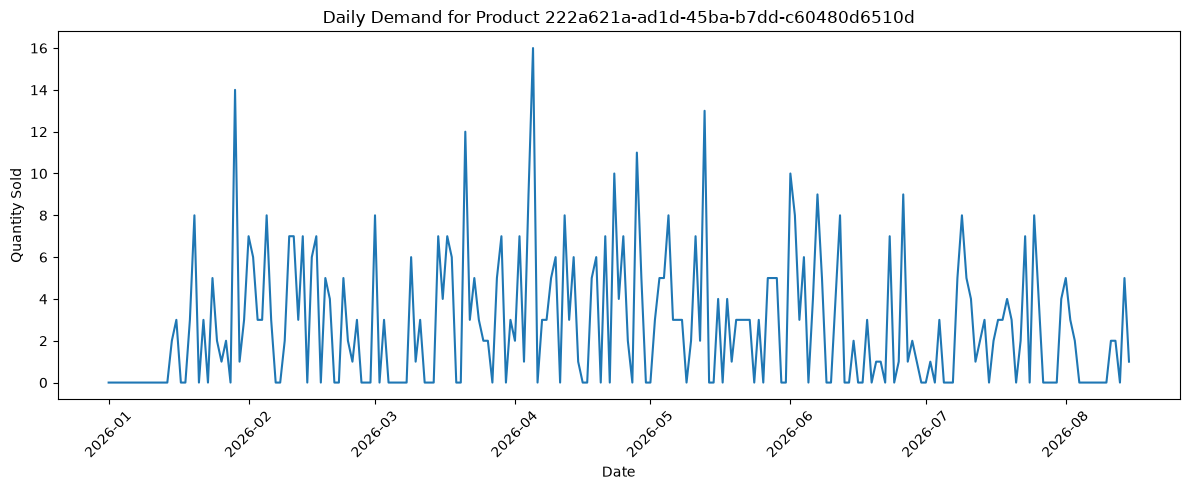

Selected product: 222a621a-ad1d-45ba-b7dd-c60480d6510d


In [5]:
top_product = (
    daily_sales.groupby("ProductID")["Demand"]
    .sum()
    .idxmax()
)

product_history = daily_sales[
    daily_sales["ProductID"] == top_product
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    product_history["Date"],
    product_history["Demand"]
)

plt.title(f"Daily Demand for Product {top_product}")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Selected product:", top_product)

In [6]:
daily_sales["ProductCode"] = (
    daily_sales["ProductID"]
    .astype("category")
    .cat.codes
)

daily_sales["DayOfWeek"] = (
    daily_sales["Date"].dt.dayofweek
)

daily_sales["DayOfMonth"] = (
    daily_sales["Date"].dt.day
)

daily_sales["Month"] = (
    daily_sales["Date"].dt.month
)

daily_sales["Lag_1"] = (
    daily_sales.groupby("ProductID")["Demand"].shift(1)
)

daily_sales["Lag_7"] = (
    daily_sales.groupby("ProductID")["Demand"].shift(7)
)

daily_sales["Lag_14"] = (
    daily_sales.groupby("ProductID")["Demand"].shift(14)
)

daily_sales["RollingMean_7"] = (
    daily_sales.groupby("ProductID")["Demand"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

daily_sales["RollingMean_14"] = (
    daily_sales.groupby("ProductID")["Demand"]
    .transform(lambda s: s.shift(1).rolling(14).mean())
)

daily_sales = daily_sales.dropna().reset_index(drop=True)

print(daily_sales.head())
print("Rows after creating lag features:", len(daily_sales))

                              ProductID       Date  Demand  ProductCode  \
0  0128933d-9879-4346-aafc-a8045c36b087 2026-01-15     2.0            0   
1  0128933d-9879-4346-aafc-a8045c36b087 2026-01-16     6.0            0   
2  0128933d-9879-4346-aafc-a8045c36b087 2026-01-17     2.0            0   
3  0128933d-9879-4346-aafc-a8045c36b087 2026-01-18     0.0            0   
4  0128933d-9879-4346-aafc-a8045c36b087 2026-01-19     3.0            0   

   DayOfWeek  DayOfMonth  Month  Lag_1  Lag_7  Lag_14  RollingMean_7  \
0          3          15      1    0.0    0.0     0.0       0.000000   
1          4          16      1    2.0    0.0     0.0       0.285714   
2          5          17      1    6.0    0.0     0.0       1.142857   
3          6          18      1    2.0    0.0     0.0       1.428571   
4          0          19      1    0.0    0.0     0.0       1.428571   

   RollingMean_14  
0        0.000000  
1        0.142857  
2        0.571429  
3        0.714286  
4        0.71428

In [7]:
from lightgbm import LGBMRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

feature_columns = [
    "ProductCode",
    "DayOfWeek",
    "DayOfMonth",
    "Month",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "RollingMean_7",
    "RollingMean_14"
]

# Use the last 14 days for testing
split_date = (
    daily_sales["Date"].max()
    - pd.Timedelta(days=13)
)

train_data = daily_sales[
    daily_sales["Date"] < split_date
].copy()

test_data = daily_sales[
    daily_sales["Date"] >= split_date
].copy()

X_train = train_data[feature_columns]
y_train = train_data["Demand"]

X_test = test_data[feature_columns]
y_test = test_data["Demand"]

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print("Training ends:", train_data["Date"].max())
print("Testing starts:", test_data["Date"].min())
print("Testing ends:", test_data["Date"].max())

Training rows: 24079
Testing rows: 1694
Training ends: 2026-08-01 00:00:00
Testing starts: 2026-08-02 00:00:00
Testing ends: 2026-08-15 00:00:00


In [8]:
lightgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=20,
    max_depth=-1,
    random_state=42,
    verbosity=-1
)

lightgbm_model.fit(
    X_train,
    y_train
)

print("LightGBM training completed.")

LightGBM training completed.


In [9]:
lightgbm_predictions = lightgbm_model.predict(X_test)

lightgbm_predictions = np.maximum(
    lightgbm_predictions,
    0
)

lightgbm_mae = mean_absolute_error(
    y_test,
    lightgbm_predictions
)

lightgbm_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        lightgbm_predictions
    )
)

lightgbm_r2 = r2_score(
    y_test,
    lightgbm_predictions
)

print("LIGHTGBM EVALUATION")

print("MAE:", round(lightgbm_mae, 3))
print("RMSE:", round(lightgbm_rmse, 3))
print("R2 Score:", round(lightgbm_r2, 3))

LIGHTGBM EVALUATION
MAE: 1.155
RMSE: 1.653
R2 Score: 0.004


In [11]:
baseline_predictions = np.maximum(
    test_data["Lag_1"].to_numpy(),
    0
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

print("MODEL COMPARISON")

print("Previous-day baseline MAE:", round(baseline_mae, 3))
print("LightGBM MAE:", round(lightgbm_mae, 3))

if lightgbm_mae < baseline_mae:
    print("LightGBM performs better than the baseline.")
else:
    print("Baseline performs better than LightGBM.")

MODEL COMPARISON
Previous-day baseline MAE: 1.407
LightGBM MAE: 1.155
LightGBM performs better than the baseline.


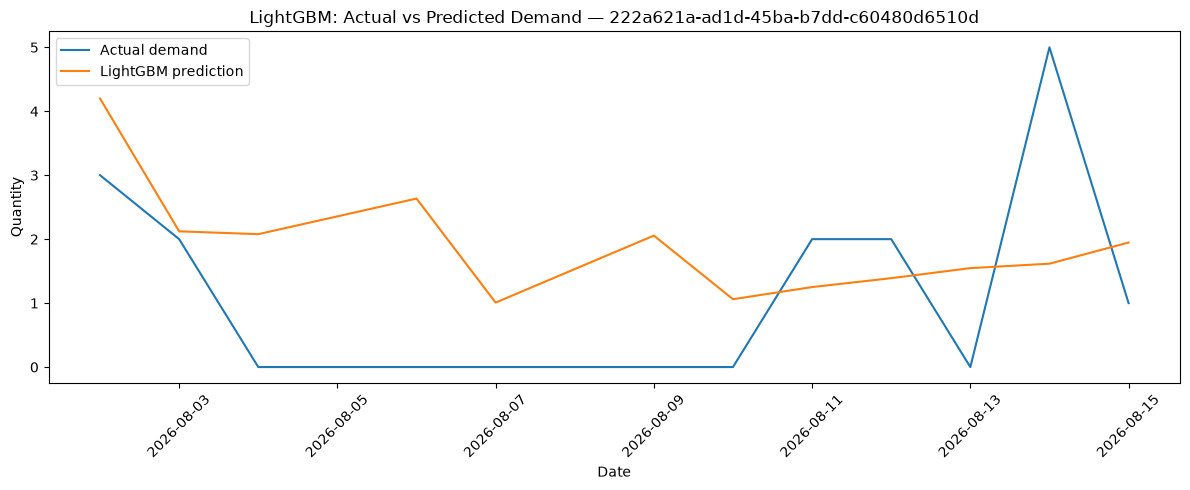

In [12]:
comparison = test_data[
    ["Date", "ProductID", "Demand"]
].copy()

comparison["PredictedDemand"] = lightgbm_predictions

product_comparison = comparison[
    comparison["ProductID"] == top_product
].sort_values("Date")

plt.figure(figsize=(12, 5))

plt.plot(
    product_comparison["Date"],
    product_comparison["Demand"],
    label="Actual demand"
)

plt.plot(
    product_comparison["Date"],
    product_comparison["PredictedDemand"],
    label="LightGBM prediction"
)

plt.title(f"LightGBM: Actual vs Predicted Demand — {top_product}")
plt.xlabel("Date")
plt.ylabel("Quantity")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
from prophet import Prophet

prophet_data = product_history[
    ["Date", "Demand"]
].rename(
    columns={
        "Date": "ds",
        "Demand": "y"
    }
)

prophet_train = prophet_data[
    prophet_data["ds"] < split_date
].copy()

prophet_test = prophet_data[
    prophet_data["ds"] >= split_date
].copy()

print("Prophet training rows:", len(prophet_train))
print("Prophet testing rows:", len(prophet_test))

Prophet training rows: 213
Prophet testing rows: 14


In [14]:
prophet_model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

print("Prophet training completed.")

22:31:53 - cmdstanpy - INFO - Chain [1] start processing
22:31:54 - cmdstanpy - INFO - Chain [1] done processing


Prophet training completed.


In [15]:
prophet_future = prophet_test[["ds"]].copy()

prophet_forecast = prophet_model.predict(
    prophet_future
)

prophet_predictions = np.maximum(
    prophet_forecast["yhat"].to_numpy(),
    0
)

prophet_actual = prophet_test["y"].to_numpy()

prophet_mae = mean_absolute_error(
    prophet_actual,
    prophet_predictions
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_actual,
        prophet_predictions
    )
)

prophet_r2 = r2_score(
    prophet_actual,
    prophet_predictions
)

print("PROPHET EVALUATION")

print("MAE:", round(prophet_mae, 3))
print("RMSE:", round(prophet_rmse, 3))
print("R2 Score:", round(prophet_r2, 3))

PROPHET EVALUATION
MAE: 2.351
RMSE: 2.569
R2 Score: -1.988


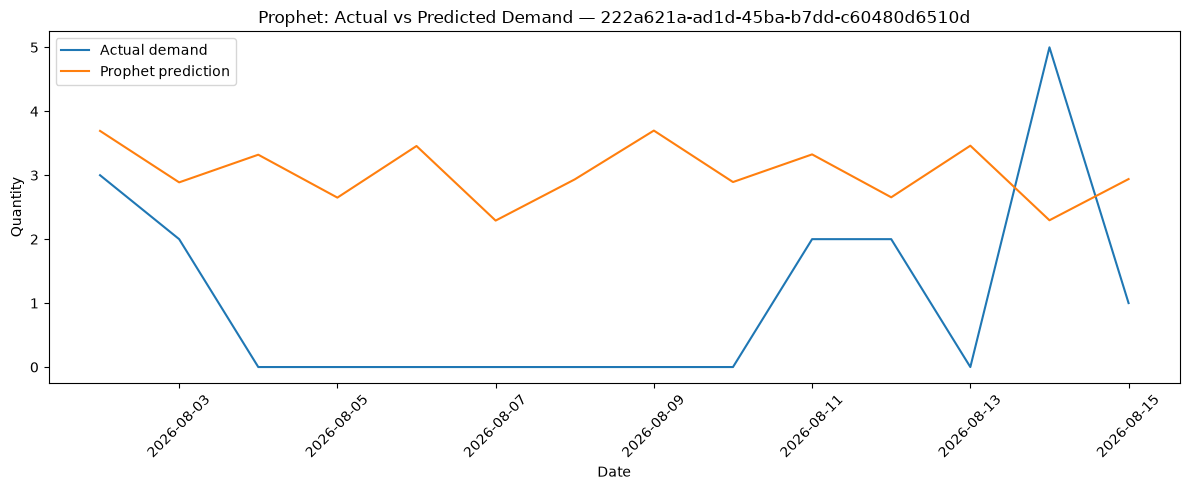

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    prophet_test["ds"],
    prophet_actual,
    label="Actual demand"
)

plt.plot(
    prophet_test["ds"],
    prophet_predictions,
    label="Prophet prediction"
)

plt.title(f"Prophet: Actual vs Predicted Demand — {top_product}")
plt.xlabel("Date")
plt.ylabel("Quantity")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
model_comparison = pd.DataFrame([
    {
        "Model": "LightGBM",
        "MAE": lightgbm_mae,
        "RMSE": lightgbm_rmse
    },
    {
        "Model": "Prophet",
        "MAE": prophet_mae,
        "RMSE": prophet_rmse
    }
])

print(
    model_comparison.sort_values("MAE")
)

      Model       MAE      RMSE
0  LightGBM  1.154528  1.652945
1   Prophet  2.350774  2.569278


In [19]:
# Create comparison for the selected product

lightgbm_product_test = comparison[
    comparison["ProductID"] == top_product
].copy()

prophet_comparison = prophet_test.merge(
    lightgbm_product_test[
        ["Date", "PredictedDemand"]
    ],
    left_on="ds",
    right_on="Date",
    how="inner"
)

# Actual demand values
actual = prophet_comparison["y"]

# LightGBM predictions
lightgbm_pred = prophet_comparison[
    "PredictedDemand"
]

# Prophet predictions
prophet_pred = prophet_predictions[
    prophet_comparison.index
]

# Evaluation results
model_comparison = pd.DataFrame([
    {
        "Model": "LightGBM",
        "MAE": mean_absolute_error(
            actual,
            lightgbm_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual,
                lightgbm_pred
            )
        ),
        "R2": r2_score(
            actual,
            lightgbm_pred
        )
    },
    {
        "Model": "Prophet",
        "MAE": mean_absolute_error(
            actual,
            prophet_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual,
                prophet_pred
            )
        ),
        "R2": r2_score(
            actual,
            prophet_pred
        )
    }
])

print("\nFINAL MODEL COMPARISON")

print(model_comparison.round(3))


FINAL MODEL COMPARISON
      Model    MAE   RMSE     R2
0  LightGBM  1.520  1.745 -0.379
1   Prophet  2.351  2.569 -1.988


In [20]:
# Prepare Prophet evaluation results
prophet_eval = prophet_test[
    ["ds", "y"]
].copy()

prophet_eval["ProphetPrediction"] = prophet_predictions

# Prepare LightGBM results
lightgbm_eval = comparison[
    comparison["ProductID"] == top_product
][["Date", "PredictedDemand"]].copy()

# Match both models by date
model_eval = prophet_eval.merge(
    lightgbm_eval,
    left_on="ds",
    right_on="Date",
    how="inner"
)

# Actual values
actual = model_eval["y"]

# Model predictions
lightgbm_pred = model_eval["PredictedDemand"]
prophet_pred = model_eval["ProphetPrediction"]

# Compare models
model_comparison = pd.DataFrame([
    {
        "Model": "LightGBM",
        "MAE": mean_absolute_error(actual, lightgbm_pred),
        "RMSE": np.sqrt(mean_squared_error(actual, lightgbm_pred)),
        "R2": r2_score(actual, lightgbm_pred)
    },
    {
        "Model": "Prophet",
        "MAE": mean_absolute_error(actual, prophet_pred),
        "RMSE": np.sqrt(mean_squared_error(actual, prophet_pred)),
        "R2": r2_score(actual, prophet_pred)
    }
])

print("Number of matching test dates:", len(model_eval))
print("\nMODEL COMPARISON")
print(model_comparison.round(3))

Number of matching test dates: 14

MODEL COMPARISON
      Model    MAE   RMSE     R2
0  LightGBM  1.520  1.745 -0.379
1   Prophet  2.351  2.569 -1.988


In [21]:
from pathlib import Path
import joblib

project_root = Path(
    "C:/Users/RSCH/Desktop/DWD/Final project/"
    "Retail-Intelligence-Platform"
)

model_dir = project_root / "backend" / "ml" / "forecasting" / "models"
model_dir.mkdir(parents=True, exist_ok=True)

print("Models will be saved in:", model_dir)

Models will be saved in: C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\backend\ml\forecasting\models


In [22]:
final_lightgbm = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=20,
    max_depth=-1,
    random_state=42,
    verbosity=-1
)

final_lightgbm.fit(
    daily_sales[feature_columns],
    daily_sales["Demand"]
)

product_code_map = (
    daily_sales[["ProductID", "ProductCode"]]
    .drop_duplicates()
)

joblib.dump(
    {
        "model": final_lightgbm,
        "feature_columns": feature_columns,
        "product_code_map": dict(
            zip(
                product_code_map["ProductID"].astype(str),
                product_code_map["ProductCode"]
            )
        )
    },
    model_dir / "lightgbm_model.pkl"
)

print("Final LightGBM model saved.")

Final LightGBM model saved.


In [23]:
import pandas as pd
import pickle
from pathlib import Path
from prophet import Prophet
from prophet.serialize import model_to_json

# Project paths
model_folder = Path(
    "../backend/ml/forecasting/models/prophet_models"
)
model_folder.mkdir(parents=True, exist_ok=True)

# Load the cleaned dataset
file_path = Path("../datasets/amez_dataset_cleaned.xlsx")

data = pd.read_excel(
    file_path,
    sheet_name="Overall_Transactions"
)

data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
data = data.dropna(subset=["ProductID", "InvoiceDate", "Quantity"])
data = data[data["Quantity"] > 0].copy()

data["Date"] = data["InvoiceDate"].dt.normalize()

# Aggregate daily demand for every product
daily_demand = (
    data.groupby(["ProductID", "Date"], as_index=False)
    .agg(Demand=("Quantity", "sum"))
)

latest_date = daily_demand["Date"].max()

# Store one model filename for each product ID
model_index = {}
training_summary = []

for product_id, product_data in daily_demand.groupby("ProductID"):

    # Create a continuous daily history for this product
    product_data = (
        product_data.set_index("Date")["Demand"]
        .sort_index()
    )

    date_range = pd.date_range(
        start=product_data.index.min(),
        end=latest_date,
        freq="D"
    )

    series = product_data.reindex(
        date_range,
        fill_value=0
    )

    prophet_data = pd.DataFrame({
        "ds": series.index,
        "y": series.values
    })

    # Skip products with insufficient history for a useful model
    nonzero_days = int((prophet_data["y"] > 0).sum())

    if len(prophet_data) < 30 or nonzero_days < 3:
        training_summary.append({
            "ProductID": product_id,
            "Status": "Insufficient history",
            "Days": len(prophet_data),
            "NonZeroDays": nonzero_days
        })
        continue

    # Train a separate Prophet model for this product
    model = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=True,
        daily_seasonality=False
    )

    model.fit(prophet_data)

    # Use a sequential filename, avoiding issues with product IDs
    model_filename = f"product_{len(model_index):04d}.json"

    with open(model_folder / model_filename, "w", encoding="utf-8") as file:
        file.write(model_to_json(model))

    model_index[str(product_id)] = model_filename

    training_summary.append({
        "ProductID": product_id,
        "Status": "Model trained",
        "Days": len(prophet_data),
        "NonZeroDays": nonzero_days
    })

# Save the mapping between ProductID and its model file
with open(model_folder / "model_index.pkl", "wb") as file:
    pickle.dump(model_index, file)

summary = pd.DataFrame(training_summary)

summary.to_csv(
    model_folder / "training_summary.csv",
    index=False
)

print("Products in daily demand data:", daily_demand["ProductID"].nunique())
print("Prophet models trained:", len(model_index))
print("Products needing fallback:", len(summary) - len(model_index))

display(summary.head(20))

22:33:33 - cmdstanpy - INFO - Chain [1] start processing
22:33:33 - cmdstanpy - INFO - Chain [1] done processing
22:33:34 - cmdstanpy - INFO - Chain [1] start processing
22:33:34 - cmdstanpy - INFO - Chain [1] done processing
22:33:35 - cmdstanpy - INFO - Chain [1] start processing
22:33:35 - cmdstanpy - INFO - Chain [1] done processing
22:33:35 - cmdstanpy - INFO - Chain [1] start processing
22:33:36 - cmdstanpy - INFO - Chain [1] done processing
22:33:36 - cmdstanpy - INFO - Chain [1] start processing
22:33:36 - cmdstanpy - INFO - Chain [1] done processing
22:33:36 - cmdstanpy - INFO - Chain [1] start processing
22:33:36 - cmdstanpy - INFO - Chain [1] done processing
22:33:37 - cmdstanpy - INFO - Chain [1] start processing
22:33:37 - cmdstanpy - INFO - Chain [1] done processing
22:33:37 - cmdstanpy - INFO - Chain [1] start processing
22:33:37 - cmdstanpy - INFO - Chain [1] done processing
22:33:38 - cmdstanpy - INFO - Chain [1] start processing
22:33:38 - cmdstanpy - INFO - Chain [1]

Products in daily demand data: 121
Prophet models trained: 121
Products needing fallback: 0


,ProductID,Status,Days,NonZeroDays
0,0128933d-9879-4346-aafc-a8045c36b087,Model trained,213,74
1,03df1a4a-b5a2-40ee-b621-f064b782d4a1,Model trained,213,79
2,04df7b21-ab56-460d-96c8-25aed6e602a0,Model trained,210,75
3,06a13e3b-0b08-40f7-bc7c-74fc8f197b7f,Model trained,211,64
4,0a7982e2-2a56-4dea-b738-821ef43ca9ae,Model trained,209,66
5,0cc93738-8436-48b6-8d99-f7b664a19913,Model trained,213,73
6,10208917-4723-496b-965e-6ba280adfe4c,Model trained,213,82
7,11deee89-170f-41d4-9a10-3c9699f9e74f,Model trained,207,65
8,1598a930-ff4a-4af9-8456-cece32f2e2f9,Model trained,213,53
9,19adee70-c411-4b5e-8916-4ce0acca7cd6,Model trained,210,63


In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Convert actual demand into categories
# 0 = No demand
# 1 = Demand occurred

actual_classes = (y_test >= 1).astype(int)

# Convert predicted demand into categories
# 0.5 is the prediction threshold
predicted_classes = (
    lightgbm_predictions >= 0.5
).astype(int)

# Calculate classification metrics
accuracy = accuracy_score(
    actual_classes,
    predicted_classes
)

precision = precision_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

recall = recall_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

f1 = f1_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

print("LIGHTGBM CLASSIFICATION-BASED EVALUATION")

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1 Score:", round(f1, 3))

print("\nConfusion Matrix:")
print(confusion_matrix(
    actual_classes,
    predicted_classes
))

LIGHTGBM CLASSIFICATION-BASED EVALUATION
Accuracy: 0.336
Precision: 0.297
Recall: 0.929
F1 Score: 0.45

Confusion Matrix:
[[ 110 1089]
 [  35  460]]


In [27]:
print("Actual demand records:", len(y_test))
print("Prophet prediction records:", len(prophet_predictions))

Actual demand records: 1694
Prophet prediction records: 14


In [29]:
print("Available variables:")

print("prophet_train:", len(prophet_train))
print("prophet_test:", len(prophet_test))
print("prophet_predictions:", len(prophet_predictions))

Available variables:
prophet_train: 213
prophet_test: 14
prophet_predictions: 14


In [31]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Actual Prophet test values
prophet_actual = prophet_test["y"].to_numpy()

# Predicted Prophet values
prophet_predicted = np.maximum(
    np.asarray(prophet_predictions).flatten(),
    0
)

# Regression evaluation
prophet_mae = mean_absolute_error(
    prophet_actual,
    prophet_predicted
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_actual,
        prophet_predicted
    )
)

prophet_r2 = r2_score(
    prophet_actual,
    prophet_predicted
)

# Classification-based evaluation
actual_classes = (prophet_actual >= 1).astype(int)

predicted_classes = (
    prophet_predicted >= 0.5
).astype(int)

prophet_accuracy = accuracy_score(
    actual_classes,
    predicted_classes
)

prophet_precision = precision_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

prophet_recall = recall_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

prophet_f1 = f1_score(
    actual_classes,
    predicted_classes,
    zero_division=0
)

print("PROPHET MODEL EVALUATION")
print("-------------------------")
print("MAE:", round(prophet_mae, 3))
print("RMSE:", round(prophet_rmse, 3))
print("R2 Score:", round(prophet_r2, 3))
print("Accuracy:", round(prophet_accuracy, 3))
print("Precision:", round(prophet_precision, 3))
print("Recall:", round(prophet_recall, 3))
print("F1 Score:", round(prophet_f1, 3))

PROPHET MODEL EVALUATION
-------------------------
MAE: 2.351
RMSE: 2.569
R2 Score: -1.988
Accuracy: 0.429
Precision: 0.429
Recall: 1.0
F1 Score: 0.6


In [32]:
model_comparison = pd.DataFrame([
    {
        "Model": "LightGBM",
        "MAE": lightgbm_mae,
        "RMSE": lightgbm_rmse,
        "R2": lightgbm_r2,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    },
    {
        "Model": "Prophet",
        "MAE": prophet_mae,
        "RMSE": prophet_rmse,
        "R2": prophet_r2,
        "Accuracy": prophet_accuracy,
        "Precision": prophet_precision,
        "Recall": prophet_recall,
        "F1 Score": prophet_f1
    }
])

print(model_comparison.round(3))

      Model    MAE   RMSE     R2  Accuracy  Precision  Recall  F1 Score
0  LightGBM  1.155  1.653  0.004     0.336      0.297   0.929      0.45
1   Prophet  2.351  2.569 -1.988     0.429      0.429   1.000      0.60


In [ ]:
joblib.dump(
    daily_sales[["ProductID", "Date", "Demand"]].copy(),
    model_dir / "daily_history.pkl"
)

print("Demand history saved successfully.")

Demand history saved successfully.
